In [104]:
import numpy as np 
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'monospace'
plt.rcParams['font.size'] = 14
from scipy.fft import rfft, irfft
from scipy.signal import fftconvolve

In [105]:
def gaussian(mu, sig):
    x = np.linspace(0, 1, 1024)
    return np.exp(-0.5 * ((x - mu) / sig) ** 2) / (sig * np.sqrt(2 * np.pi))

narrow_kernel = gaussian(0.5, 0.05)
wide_kernel = gaussian(0.5, 0.1)
pulse = gaussian(0.5, 0.01)
pulse /= np.max(pulse)

Period version:

In [106]:
narrow_convolution = fftconvolve(pulse, narrow_kernel / narrow_kernel.sum(), mode='same')
wide_convolution   = fftconvolve(pulse, wide_kernel / wide_kernel.sum(),   mode='same')

Frequency version:

In [107]:
pulse_fft = rfft(pulse)[1:]
pulse_dc  = rfft(pulse)[0]

narrow_kernel_fft = rfft(narrow_kernel)[1:]
narrow_kernel_fft /= max(np.abs(narrow_kernel_fft))
narrow_convolution_fft = narrow_kernel_fft[:len(pulse_fft)] * pulse_fft
narrow_convolution_ifft = irfft(np.r_[pulse_dc, narrow_convolution_fft], n=1024)
narrow_convolution_ifft = np.roll(narrow_convolution_ifft, 512)


wide_kernel_fft = rfft(wide_kernel)[1:]
wide_kernel_fft /= max(np.abs(wide_kernel_fft))
wide_convolution_fft = wide_kernel_fft[:len(pulse_fft)] * pulse_fft
wide_convolution_ifft = irfft(np.r_[pulse_dc, wide_convolution_fft], n=1024)
wide_convolution_ifft = np.roll(wide_convolution_ifft, 512)

Updated frequency version:

In [108]:
pulse_fft_new = rfft(pulse)
pulse_ifft_new = -irfft(pulse_fft_new)

narrow_kernel_fft_new = rfft(narrow_kernel)
narrow_kernel_fft_new /= max(np.abs(narrow_kernel_fft_new))
narrow_convolution_fft_new = narrow_kernel_fft_new[:len(pulse_fft_new)] * pulse_fft_new
narrow_convolution_ifft_new = irfft(narrow_convolution_fft_new)
narrow_convolution_ifft_new = irfft(narrow_convolution_fft_new, n=1024) 
narrow_convolution_ifft_new = np.roll(narrow_convolution_ifft_new, 512)

wide_kernel_fft_new = rfft(wide_kernel)
wide_kernel_fft_new /= max(np.abs(wide_kernel_fft_new))
wide_convolution_fft_new = wide_kernel_fft_new[:len(pulse_fft_new)] * pulse_fft_new
wide_convolution_ifft_new = irfft(wide_convolution_fft_new, n = 1024)
wide_convolution_ifft_new = np.roll(wide_convolution_ifft_new, 512)

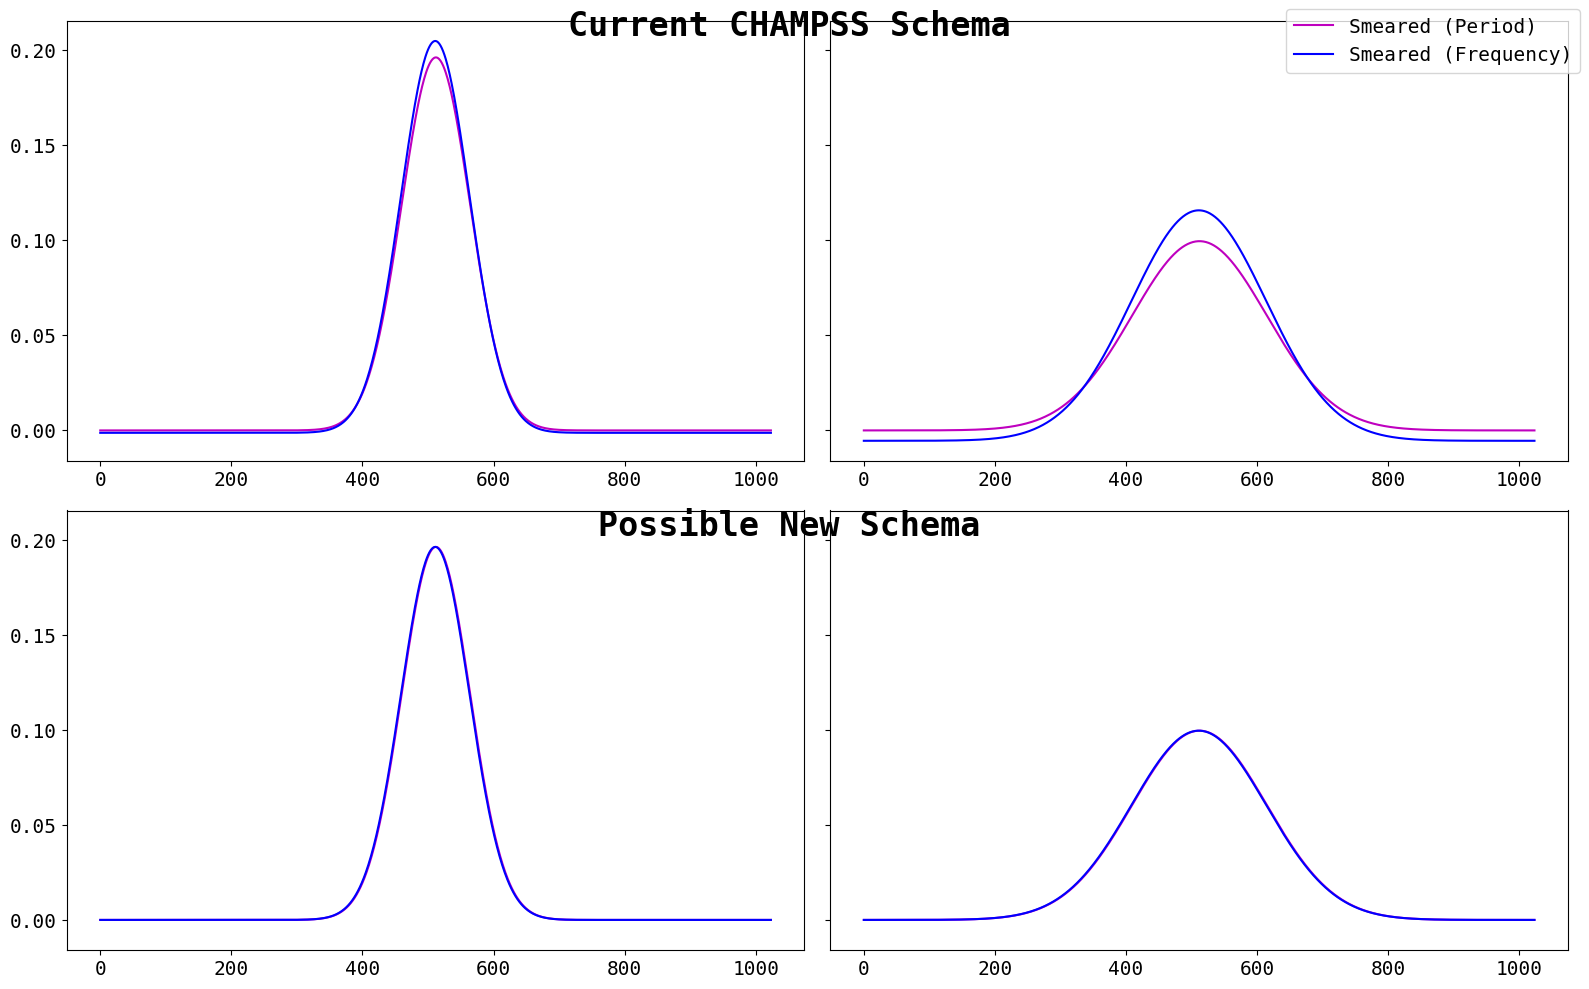

In [112]:
fig, ax = plt.subplots(2, 2, figsize = (16, 10), sharey = True)

#ax[0, 0].plot(pulse, 'r--', label = "Original Pulse")
ax[0, 0].plot(narrow_convolution, 'm', label = "Smeared (Period)")
#ax[0, 1].plot(pulse, 'r--')
ax[0, 1].plot(wide_convolution, 'm')
ax[0, 0].plot(narrow_convolution_ifft, 'b', label = "Smeared (Frequency)")
ax[0, 1].plot(wide_convolution_ifft, 'b')

#ax[1, 0].plot(pulse, 'r--')
ax[1, 0].plot(narrow_convolution, 'm')
#ax[1, 1].plot(pulse, 'r--')
ax[1, 1].plot(wide_convolution, 'm')
ax[1, 0].plot(narrow_convolution_ifft_new, 'b')
ax[1, 1].plot(wide_convolution_ifft_new, 'b')

subfigs = fig.subfigures(nrows=2, ncols=1)
subfigs[0].suptitle('Current CHAMPSS Schema', fontsize = 24, fontweight = 'bold')
subfigs[1].suptitle('Possible New Schema', fontsize = 24, fontweight = 'bold')
fig.legend()
plt.tight_layout()